In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms

import seaborn as sns
import os
import datetime
import pickle

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from collections import Counter

### Load files

In [5]:
save_flag = False

In [6]:
implantinfo_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
featdf_path = 'data/processed/ecogfeatures/plv_postproc/%s_trigger-Scheduled.csv'
outsupfig_dir = 'output/circpaper_figures/supp/'

implantdf = pd.read_csv(implantinfo_path)
patient_list = ccutils.final_patient_list()

In [7]:
### number of patients
print(f'Number of patients: {len(patient_list)}')

Number of patients: 38


### Counts

In [8]:
# read the feature csv file and count number of recording for each hour

implant_info_patlist = implantdf['npe_code'].to_list()

countdf = []

for patient_id in patient_list[:]:
    
    # read data
    featdf = pd.read_csv(featdf_path % (patient_id))
    featdf['Round_local_hour'] = featdf['Round local timestamp'].apply(lambda x: datetime.datetime.fromisoformat(x).hour).values
    
    # check if patient is available in the implant dataframe
    if patient_id in implant_info_patlist:
        implant_date = datetime.datetime.fromisoformat(implantdf.loc[implantdf['npe_code']==patient_id]['implant_date'].item())
        utils.tfromstart_days(featdf, start_date=implant_date)  # time from the date of implantation
        
    else:  # implant info unavailable; use the recordings dataframe to pick the start of recordings
        utils.tfromstart_days(featdf)  # time from start of recordings in days
        print(f'>> {patient_id}: Implant date NOT AVAILABLE.')

    # update counts
    countdf.append( pd.Series(data=Counter(featdf['Round_local_hour'].values), 
                              name=patient_id) )

# convert to dataframe
countdf = pd.concat(countdf, axis=1, ignore_index=False).T
countdf.replace(to_replace=np.nan, value=0, inplace=True)
countdf = countdf[sorted(countdf.columns)]

### plotting - pooled across patients

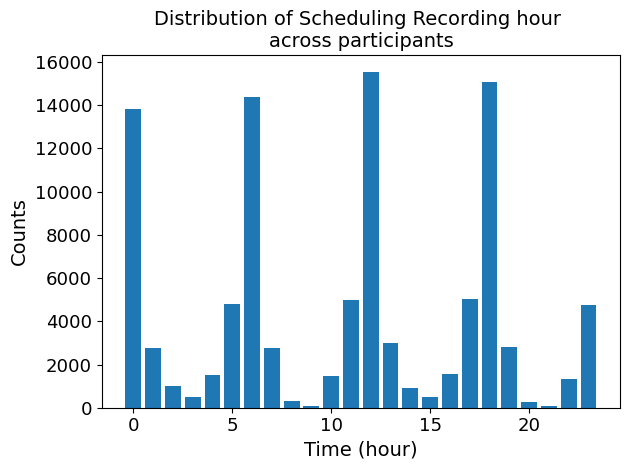

In [9]:
across_pats = countdf.sum(axis=0)

plt.bar(across_pats.index, across_pats)
plt.xlabel('Time (hour)', fontsize=14)
plt.ylabel('Counts', fontsize=14)
plt.tick_params(labelsize=13)
plt.title('Distribution of Scheduling Recording hour \nacross participants', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'recording_time_dist_pooled.pdf', dpi=300)

plt.show()

### per patient heatmap

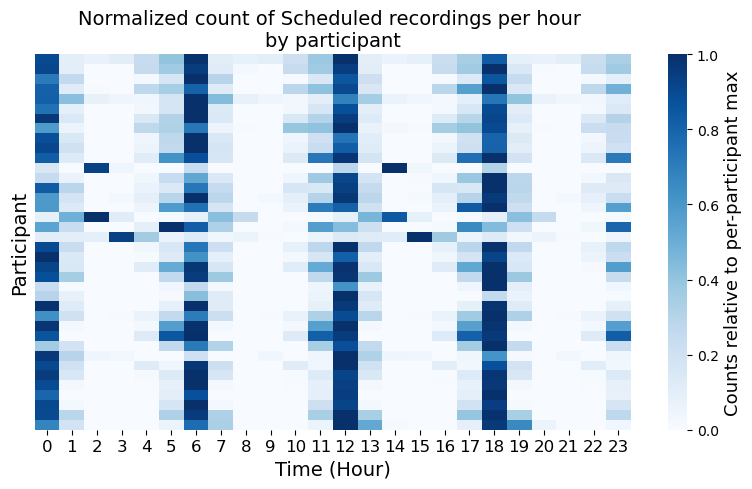

In [10]:
# Normalize per patient (row) so each row sums to 1
norm_df = countdf.div(countdf.max(axis=1), axis=0)

plt.figure(figsize=(8, 5))
ax = sns.heatmap(norm_df, cmap="Blues")
ax.collections[0].colorbar.ax.set_ylabel("Counts relative to per-participant max", fontsize=13)
plt.xlabel("Time (Hour)", fontsize=14)
plt.ylabel("Participant", fontsize=14)
plt.title("Normalized count of Scheduled recordings per hour \nby participant", fontsize=14)
plt.yticks(ticks=[])
plt.tick_params(labelsize=12)
plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'recording_time_dist_perpatient.pdf', dpi=300)

plt.show()